In [1]:
# Imports
import pandas as pd
import os
import matplotlib.pyplot as plt
import textwrap
import sys

sys.path.insert(0, os.path.abspath(".."))

In [29]:
# Plain-language names for the figures; the data keeps the codes


PLAIN_LABELS = {
    # Rebate policy scenarios
    "unsub": "No rebate",
    "sub": "IRA rebate",
    "sub_june2026": "IRA - only electric",
    "sub_local": "Local rebate",

    # Replacement offset scopes: which avoided replacement is credited
    "heatingSavings_coolingLCC": "AC replacement",
    "heatingLCC_coolingSavings": "Heating replacement",
    "heatingLCC_coolingLCC": "AC and heating replacement",
}

missing_labels = [c for c in SCOPE_ORDER + REBATE_ORDER if c not in PLAIN_LABELS]
if missing_labels:
    raise KeyError(f"PLAIN_LABELS has no plain name for: {missing_labels}")


In [2]:
# The notebook runs from cmu_tare_model/, like the main notebook
OUTPUT_FOLDER_PATH = "output_results"
COMPARISON_PATH = os.path.join(
    OUTPUT_FOLDER_PATH, "scenario_results_comparison.csv"
)

# Read time stamps as text, since result file names use them exactly
df_comparison = pd.read_csv(COMPARISON_PATH, dtype={"datetime": str})

# Oldest first (these time stamps sort as text)
RUN_DATETIMES = sorted(df_comparison["datetime"].unique())

print(f"{len(RUN_DATETIMES)} unique run(s): {RUN_DATETIMES}")

3 unique run(s): ['2026-10-30_11-37', '2026-10-30_12-26', '2026-11-02_12-26']


In [3]:
# A reloaded run is logged again under the same time stamp, so keep only
# each run's latest log. The older logs stay in the CSV.
latest_logged = df_comparison.groupby("datetime")["logged at"].transform("max")
is_latest_log = df_comparison["logged at"] == latest_logged
df_latest = df_comparison[is_latest_log].reset_index(drop=True)

rows_per_log = df_latest.groupby(["datetime", "logged at"]).size()
print(f"{len(df_comparison)} rows in the CSV, {len(df_latest)} kept")
print(rows_per_log.to_string())

114 rows in the CSV, 81 kept
datetime          logged at       
2026-10-30_11-37  2026-11-05_16-19    27
2026-10-30_12-26  2026-11-05_16-10    27
2026-11-02_12-26  2026-11-05_16-32    27


In [4]:
#settings for all fontsizes
FIGURE_FONT_SIZES = {
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 12,
}
plt.rcParams.update(FIGURE_FONT_SIZES)


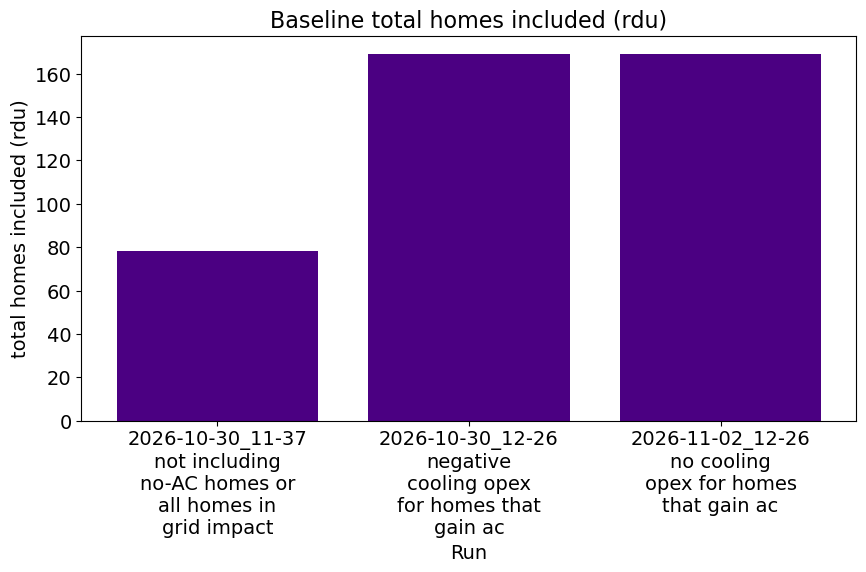

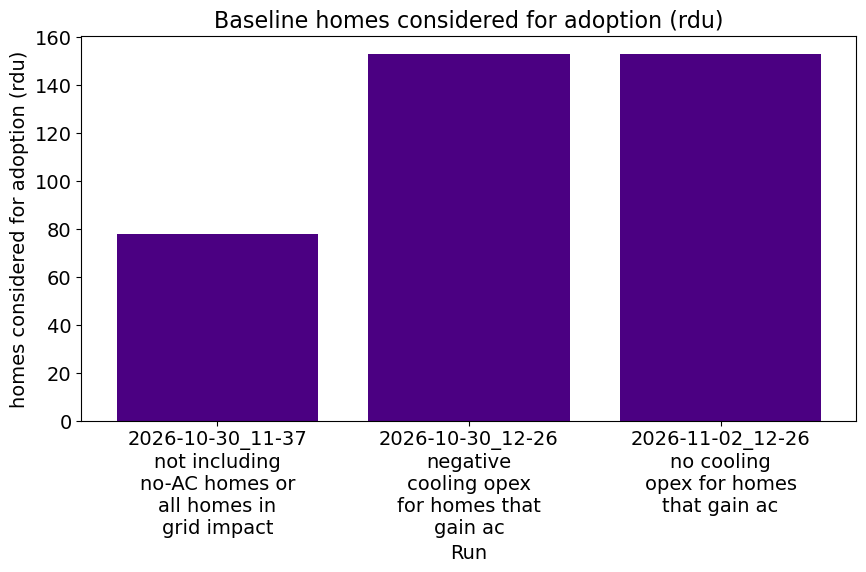

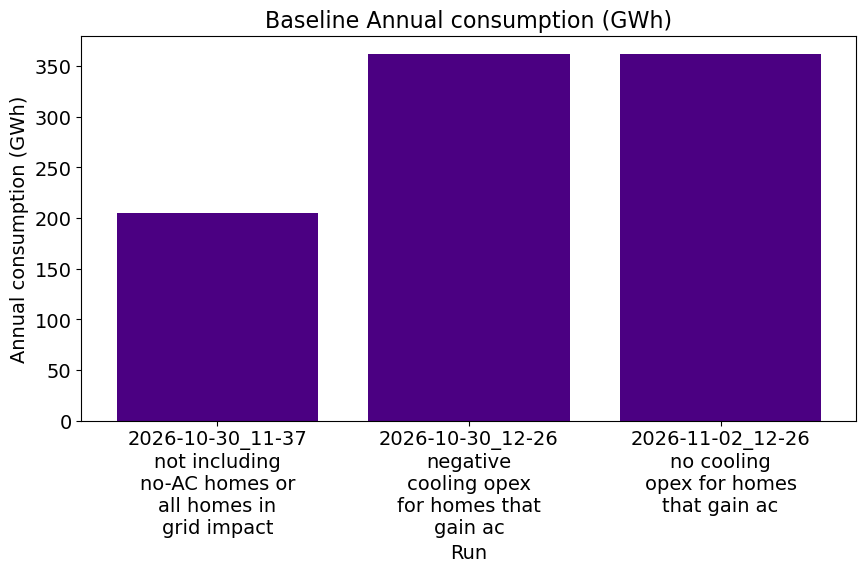

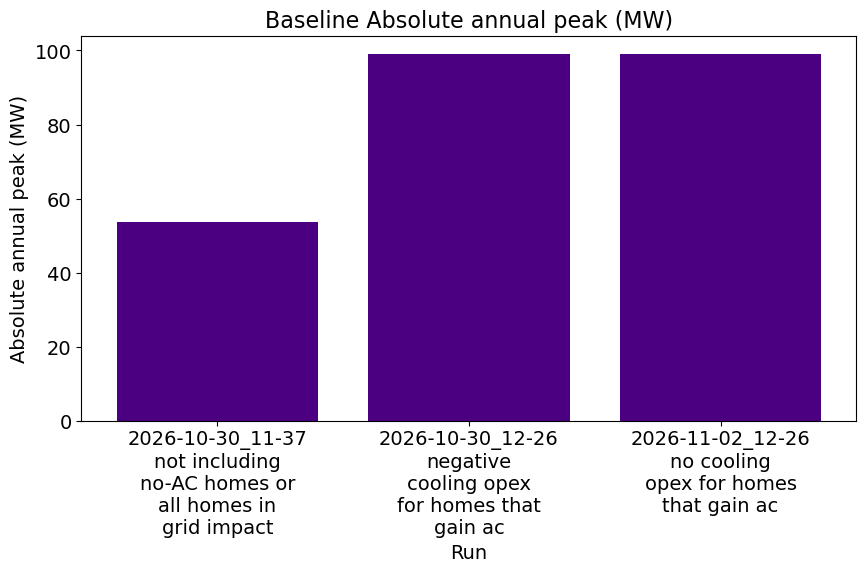

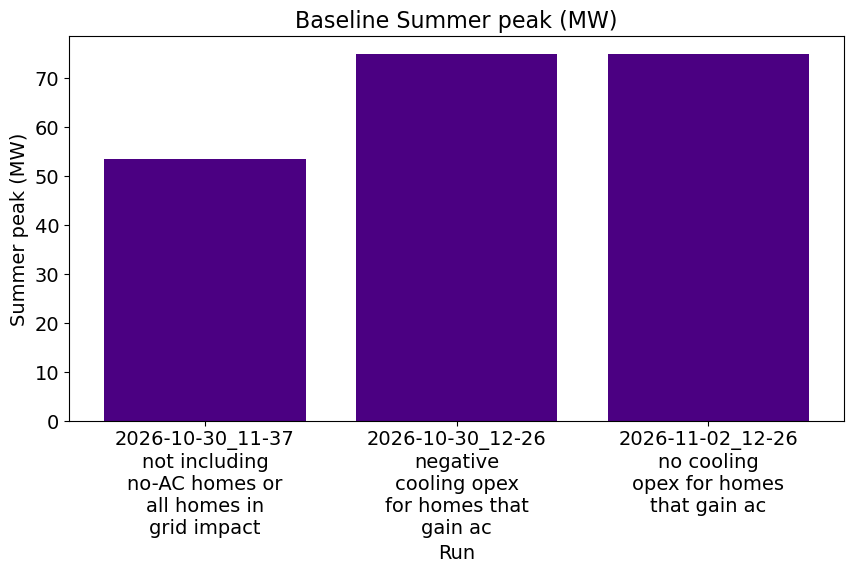

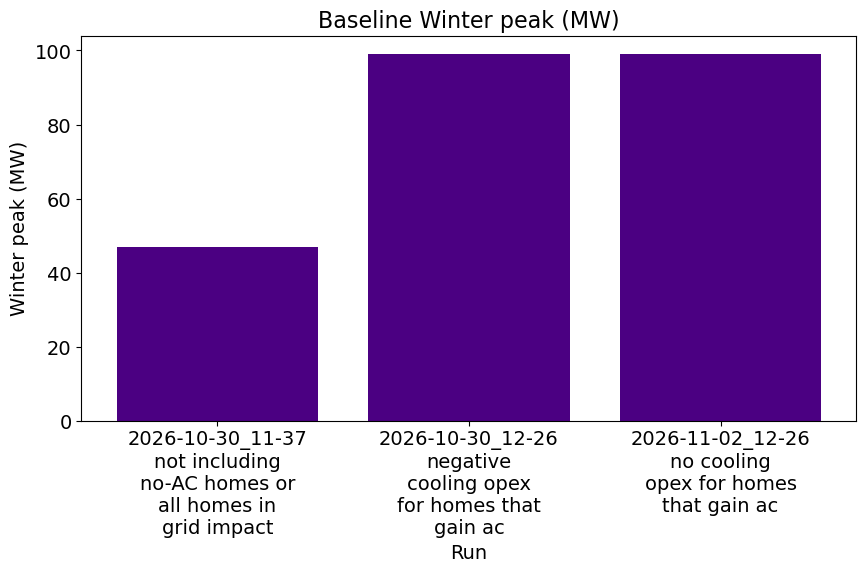

In [19]:
#Compares metrics for baseline scenarios across runs

#helper funciton for comparison bar charts
def metric_comparison_bar_chart(
        summary_df,
        metric,
        title = "",
        label_col="scenario",
        xlabel="Scenario",
        rotation=90,
        figsize = (10,5)
        ):

    # A new figure each call, so a loop gives one chart per metric
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(summary_df[label_col], summary_df[metric], color='#4B0082')
    ax.set_title(f'{title} {metric}')
    ax.set_ylabel(metric)
    ax.set_xlabel(xlabel)
    ax.tick_params(axis="x", labelrotation=rotation)
    plt.show()




baseline_metrics = [
    'total homes included (rdu)', 
    'homes considered for adoption (rdu)',
    'Annual consumption (GWh)',
    'Absolute annual peak (MW)', 
    'Summer peak (MW)', 
    'Winter peak (MW)',
]

# A run can be logged more than once; keep its last Baseline row
df_baseline = (
    df_comparison[df_comparison["Scenario"] == "Baseline"]
    .sort_values("logged at")
    .drop_duplicates(subset="datetime", keep="last")
    .sort_values("datetime")
    .reset_index(drop=True)
)

# Creates the labels for hte bar charts
# label - run timestamp and then description 
df_baseline["run_label"] = (
    df_baseline["datetime"]
    + "\n"
    + df_baseline["description"].fillna("").apply(
        lambda text: textwrap.fill(text, 14)
    )
)


for metric in baseline_metrics:
    metric_comparison_bar_chart(
        df_baseline, metric, label_col="run_label", xlabel="Run", rotation=0, title = "Baseline"
    )


In [6]:
#Rebate scenario comparisons 

all_metrics = ['datetime',
           'location', 
           'description', 
           'logged at',   
           'total homes included (rdu)', 
           'homes considered for adoption (rdu)',
           'Adopters (rdu)', 
           'Adopters (% of rdu)',
           'Adopters (% weighted)', 
           'Annual consumption (GWh)',
           'Absolute annual peak (MW)',
           'Summer peak (MW)', 
           'Winter peak (MW)'
]

#Within a given scenario, show how adoption annual energy consumption, and absolute 
#peak change by rebate scenario
metrics = ['Adopters (% of rdu)',
           'Adopters (% weighted)', 
           'Annual consumption (GWh)',
           'Absolute annual peak (MW)',
           ]




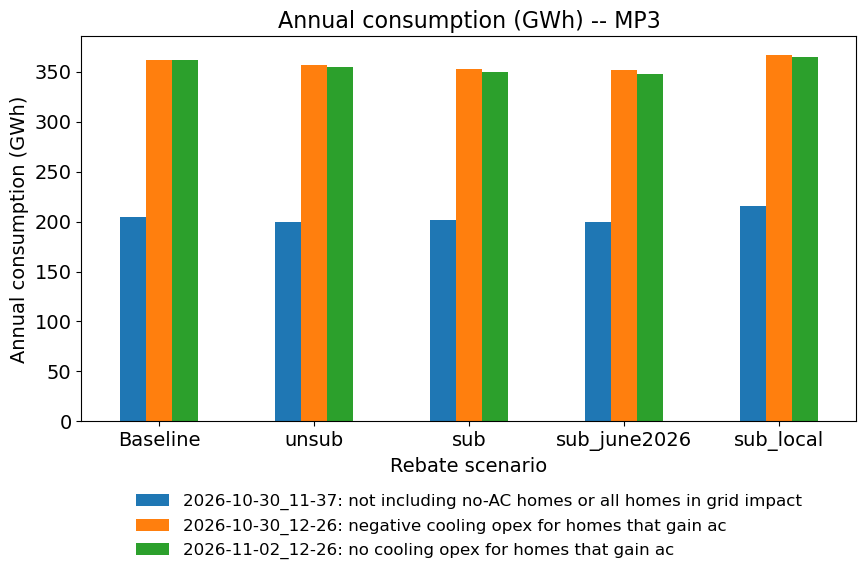

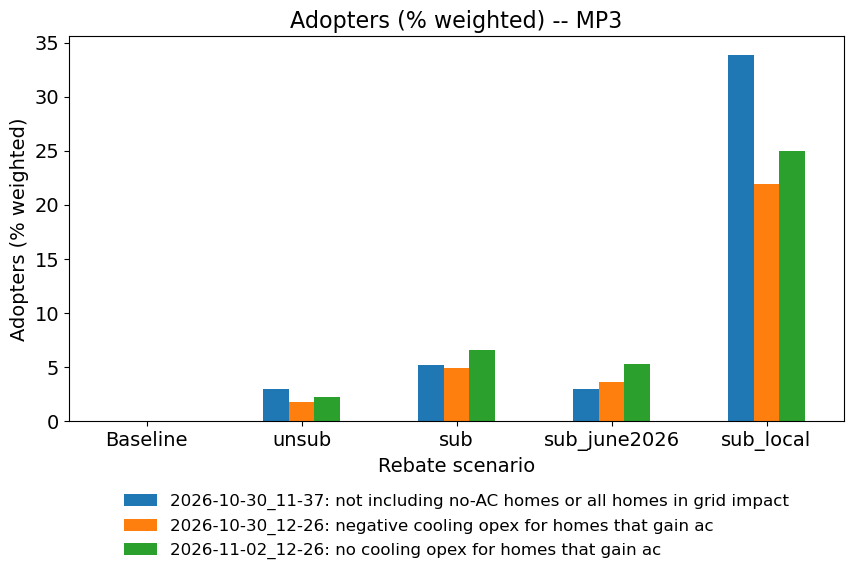

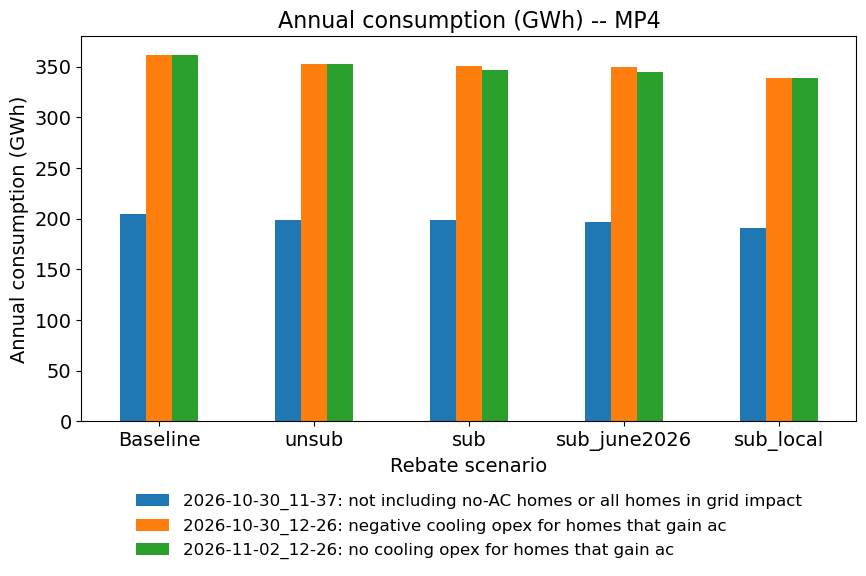

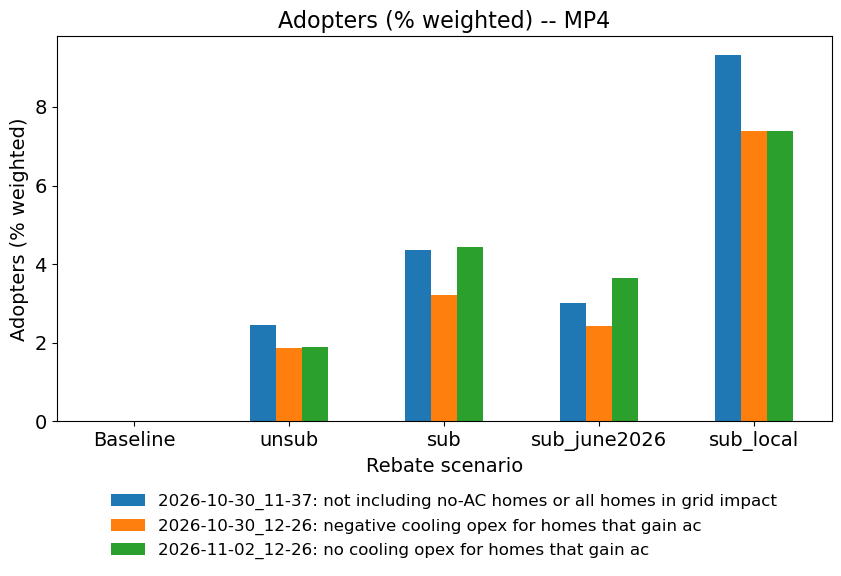

In [7]:

def plot_metric_by_rebate_scenario(df, metric, mp):
    """Clustered bars: one cluster per rebate scenario, one bar per run."""
    # Baseline has no MP, so keep it with every package
    df_plot = df[(df["Scenario"] == "Baseline") | (df["MP"] == mp)].copy()
    df_plot = df_plot[df_plot["Scenario"] != "100pct"]

    # Short cluster names, and a key label for each run
    df_plot["Rebate scenario"] = df_plot["Scenario"].str.replace(
        "heatingSavings_coolingLCC_", ""
    )
    df_plot["Run"] = df_plot["datetime"] + ": " + df_plot["description"]

    # One row per rebate scenario, one column per run
    df_wide = df_plot.pivot(
        index="Rebate scenario", columns="Run", values=metric
    )
    df_wide = df_wide.reindex(
        ["Baseline", "unsub", "sub", "sub_june2026", "sub_local"]
    )

    ax = df_wide.plot.bar(figsize=(10, 5), rot=0)
    ax.set_title(f"{metric} -- MP{mp}")
    ax.set_ylabel(metric)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
    plt.show()


for mp in [3, 4]:
    for metric in ["Annual consumption (GWh)", "Adopters (% weighted)"]:
        plot_metric_by_rebate_scenario(df_latest, metric, mp)


In [77]:
SCOPE_ORDER = [
    "heatingSavings_coolingLCC",
    "heatingLCC_coolingSavings",
    "heatingLCC_coolingLCC",
]
REBATE_ORDER = ["unsub", "sub", "sub_june2026", "sub_local"]
ENERGY_METRICS = [
    "Annual consumption (GWh)",
    "Absolute annual peak (MW)",
    "Summer peak (MW)",
    "Winter peak (MW)",
]


def add_comparison_columns(df):
    """Split Scenario into scope and rebate, label runs, add % change."""
    df = df.copy()

    # NPV case names are {heating}_{cooling}_{rebate}
    is_npv_case = ~df["Scenario"].isin(["Baseline", "100pct"])
    parts = df.loc[is_npv_case, "Scenario"].str.split("_", n=2, expand=True)
    df.loc[is_npv_case, "scope"] = parts[0] + "_" + parts[1]
    df.loc[is_npv_case, "rebate"] = parts[2]

    # Baseline has no MP; each MP has its own 100% case
    df["case"] = df["Scenario"]
    is_100pct = df["Scenario"] == "100pct"
    df.loc[is_100pct, "case"] = (
        "MP" + df.loc[is_100pct, "MP"].astype(int).astype(str) + " 100%"
    )

    df["run"] = df["datetime"] + ": " + df["description"]

    # Change from each run's own baseline, so runs of different size compare
    df_base = df[df["Scenario"] == "Baseline"].set_index("datetime")
    for metric in ENERGY_METRICS:
        run_baseline = df["datetime"].map(df_base[metric])
        change_col = metric.split(" (")[0] + " change from baseline (%)"
        df[change_col] = (df[metric] - run_baseline) / run_baseline * 100

    return df


def plot_clustered(df, metric, x, hue, x_order=None, hue_order=None,
                   title=None, baseline=None, colormap=None):
    """Clustered bars: one cluster per value of x, one color per value of hue."""
    df_wide = df.pivot(index=x, columns=hue, values=metric)
    if x_order is not None:
        df_wide = df_wide.reindex(x_order)
    if hue_order is not None:
        df_wide = df_wide.reindex(columns=hue_order)
    
    # Plain names for the chart only; codes not in PLAIN_LABELS stay as they are
    df_wide = df_wide.rename(index=PLAIN_LABELS, columns=PLAIN_LABELS)

    
    # Wrap long cluster names so neighbouring labels do not overlap
    df_wide.index = [textwrap.fill(str(name), 12) for name in df_wide.index]


    ax = df_wide.plot.bar(figsize=(8, 3.5), rot=0, colormap=colormap)
    if baseline is not None and pd.notna(baseline):
        ax.axhline(baseline, color="black", linestyle="--", label="Baseline")
    
    # Wrap long names so they fit the figure; widths are in characters
    #Wrap each line on its own, so a line break in the title is kept
    title_lines = (title or metric).split("\n")
    ax.set_title("\n".join(textwrap.fill(line, 45) for line in title_lines))

    ax.set_ylabel(textwrap.fill(metric, 22))
    ax.set_xlabel("")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
    plt.show()


df_cmp = add_comparison_columns(df_latest)


Figures for Baseline Energy Consumption


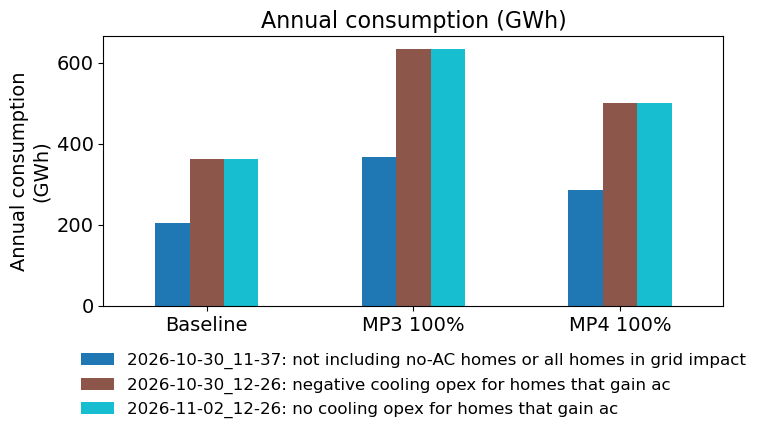

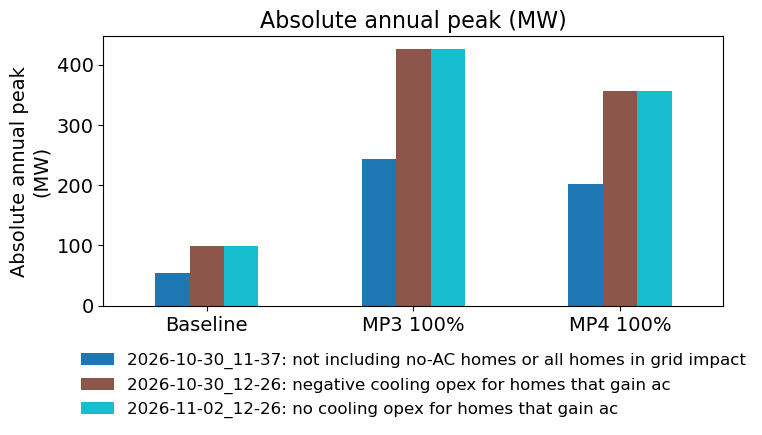

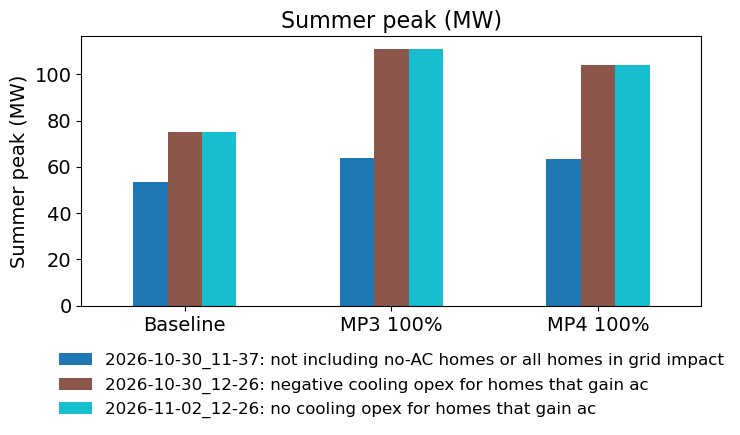

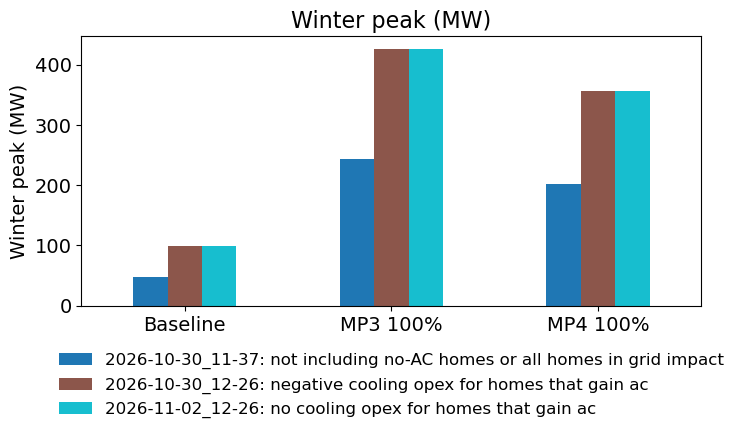

In [78]:
# 1) Baselines and 100% adoption across runs - use to validate
print(f"Figures for Baseline Energy Consumption")

df_ref = df_cmp[df_cmp["Scenario"].isin(["Baseline", "100pct"])]
for metric in ENERGY_METRICS:
    plot_clustered(df_ref, metric, x="case", hue="run", colormap="tab10",
                   x_order=["Baseline", "MP3 100%", "MP4 100%"])


In [79]:
# Checks the  Baseline bar against the run log totals
RUN_LOG_PATH = os.path.join(OUTPUT_FOLDER_PATH, "run_log.csv")
df_run_log = pd.read_csv(RUN_LOG_PATH, dtype={"datetime": str})
log_cols = ["datetime", "baseline peak load (MW)", "baseline annual energy (GWh)"]

# The same rows Figure 1 draws in its Baseline cluster
df_base_bars = df_ref.loc[
    df_ref["case"] == "Baseline",
    ["datetime", "Absolute annual peak (MW)", "Annual consumption (GWh)"],
]
df_check = df_base_bars.merge(
    df_run_log[log_cols], on="datetime", how="left", validate="one_to_one"
)

# The run log rounds to 2 decimals, so compare at 2 decimals
peak_ok = (
    df_check["Absolute annual peak (MW)"].round(2)
    == df_check["baseline peak load (MW)"]
)
energy_ok = (
    df_check["Annual consumption (GWh)"].round(2)
    == df_check["baseline annual energy (GWh)"]
)
df_check["match"] = peak_ok & energy_ok
print(df_check.to_string(index=False))

if df_check["match"].all():
    print(f"[OK] All {len(df_check)} Baseline bars match the run log")
else:
    print("[CHECK] A Baseline bar differs from the run log")


        datetime  Absolute annual peak (MW)  Annual consumption (GWh)  baseline peak load (MW)  baseline annual energy (GWh)  match
2026-10-30_12-26                      99.03                    361.86                    99.03                        361.86   True
2026-10-30_11-37                      53.56                    204.56                    53.56                        204.56   True
2026-11-02_12-26                      99.03                    361.86                    99.03                        361.86   True
[OK] All 3 Baseline bars match the run log


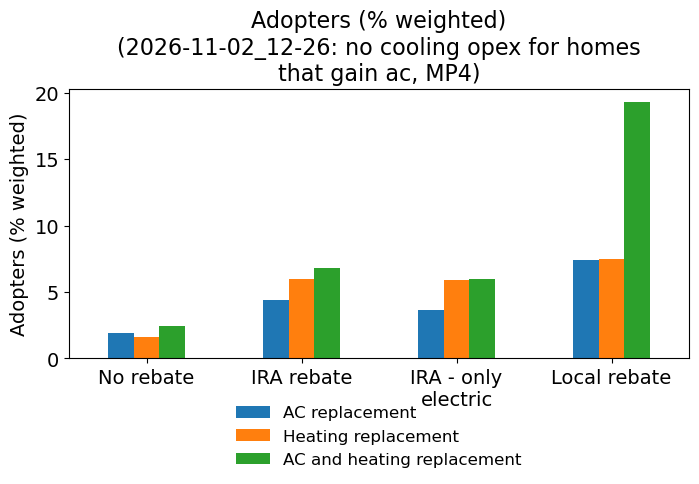

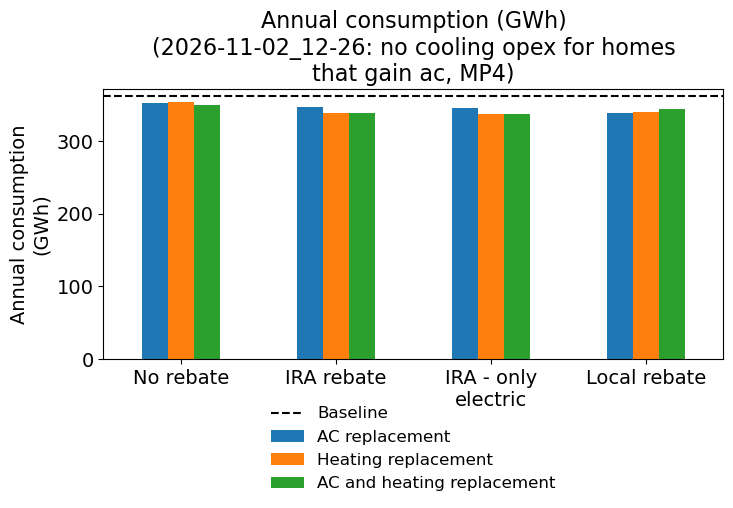

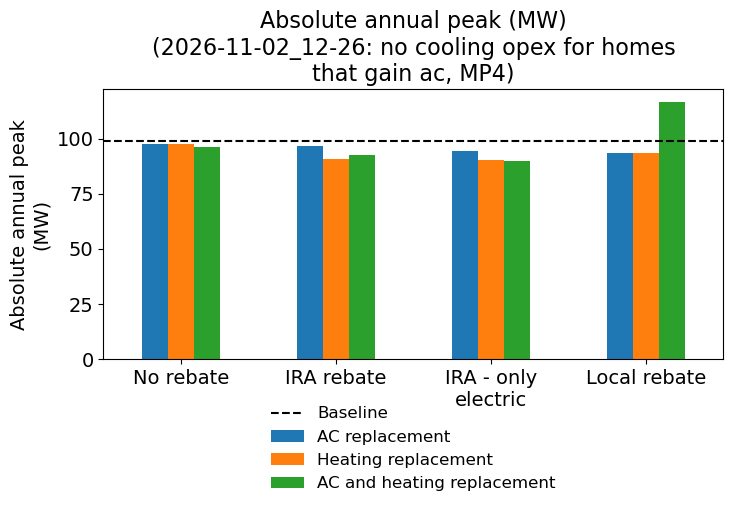

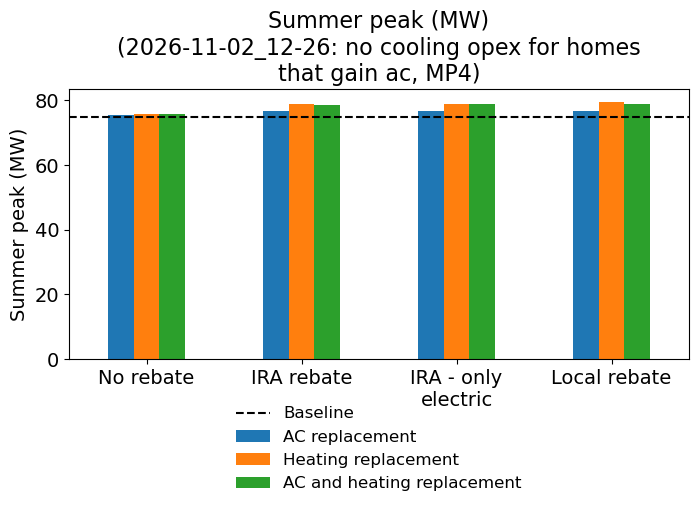

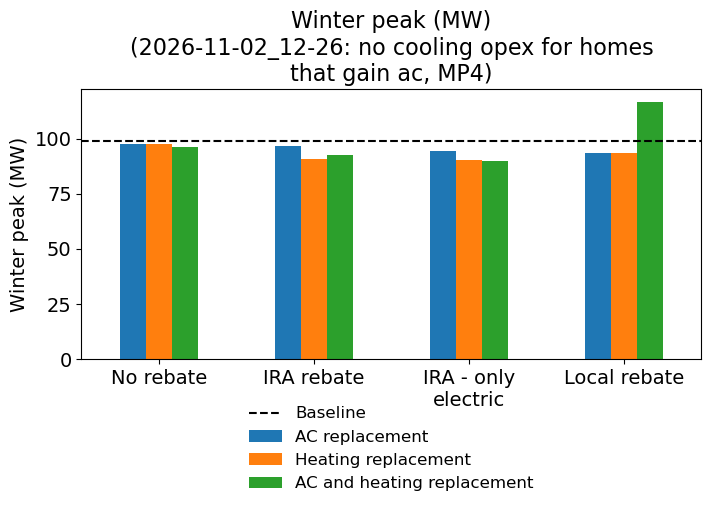

In [80]:
#Plots weighted adoption and energy metrics for a given scenario by subsidy level and replacement offset 
#Can change to visualize for MP3 or MP4

run, mp = RUN_DATETIMES[-1], 4
is_run = df_cmp["datetime"] == run
df_run = df_cmp[is_run & (df_cmp["MP"] == mp) & df_cmp["scope"].notna()]

# Time stamp and description of the run, for the titles
run_label = df_cmp.loc[
    is_run & (df_cmp["Scenario"] == "Baseline"), "run"].item()

for metric in ["Adopters (% weighted)"]+ ENERGY_METRICS:
    run_baseline = df_cmp.loc[
        is_run & (df_cmp["Scenario"] == "Baseline"), metric
    ].item()
    plot_clustered(df_run, metric, x="rebate", hue="scope",
                   x_order=REBATE_ORDER, hue_order=SCOPE_ORDER,
                   title=f"{metric} \n({run_label}, MP{mp})", baseline=run_baseline)



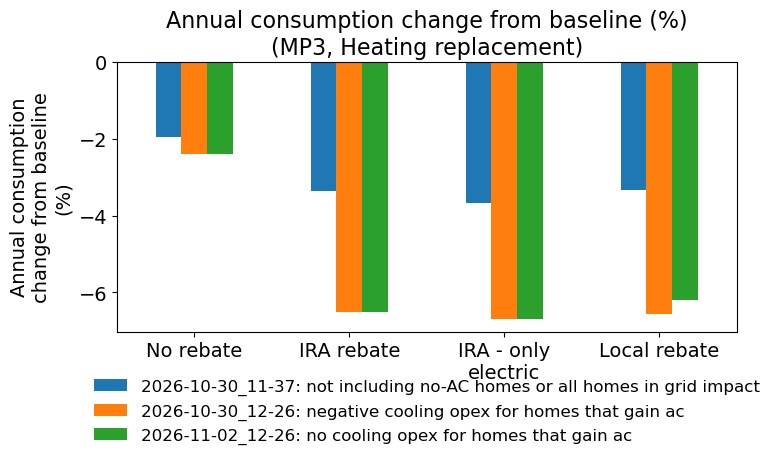

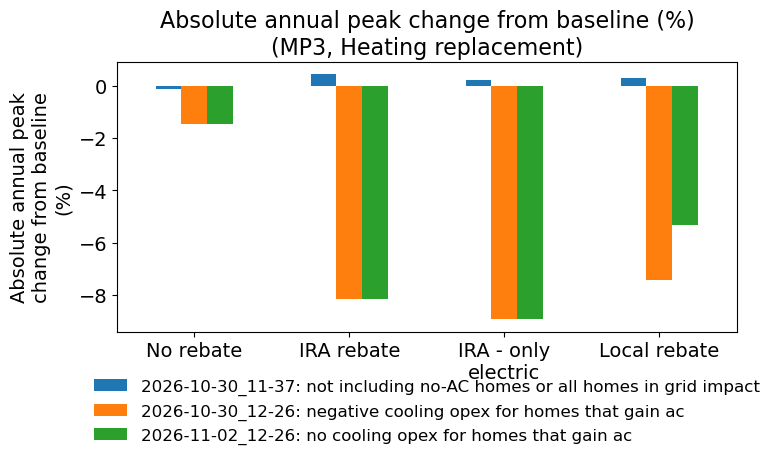

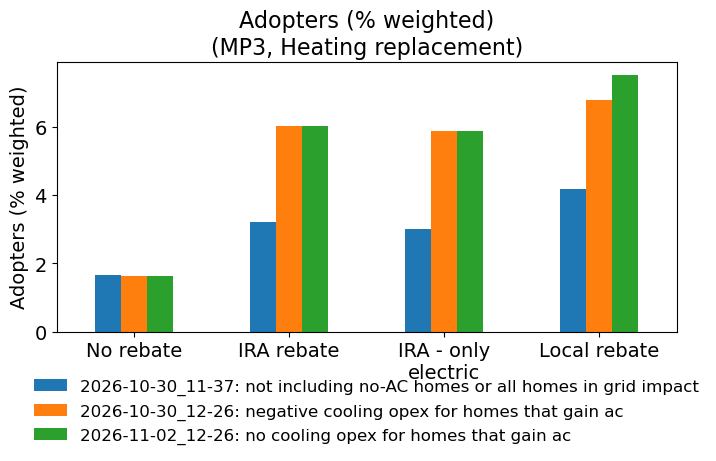

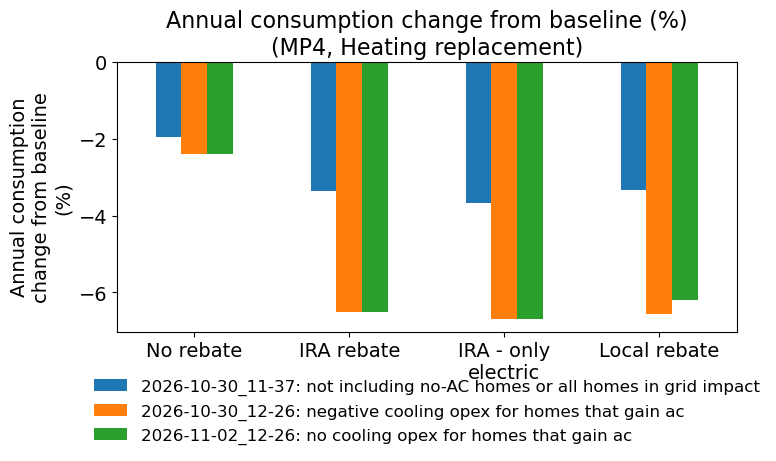

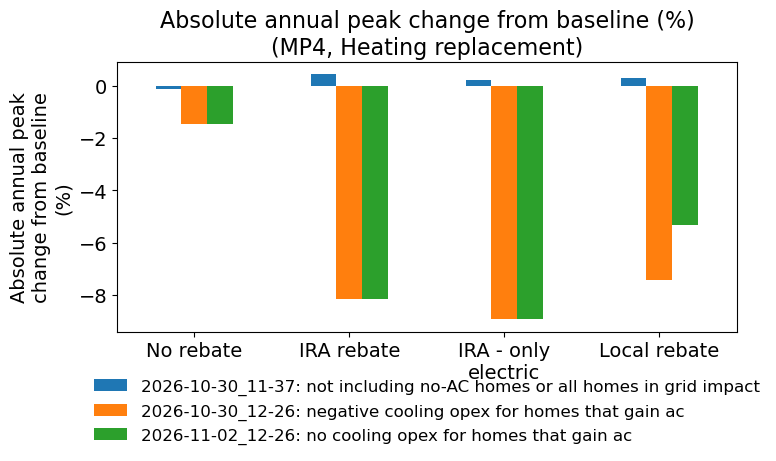

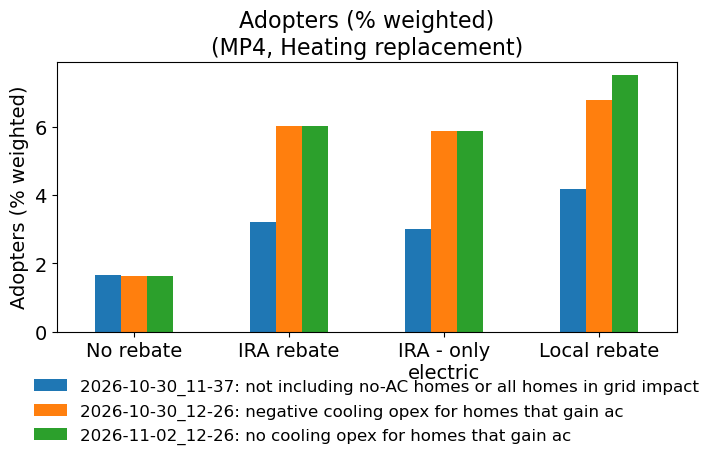

In [81]:
# Inter-model comparison
# Plots changes in annual consumption and peak change relative to baseline
# Bars for each model run clustered by rebate scenario
# Replacement offset held constant

replacement_offset = "heatingLCC_coolingSavings"

df_scope = df_cmp[(df_cmp["MP"] == mp) & (df_cmp["scope"] == replacement_offset)]

for mp in [3, 4]:
    for metric in ["Annual consumption change from baseline (%)",
                "Absolute annual peak change from baseline (%)",
                "Adopters (% weighted)"]:
        plot_clustered(df_scope, metric, x="rebate", hue="run",
                    x_order=REBATE_ORDER, 
                    title=f"{metric} \n(MP{mp}, {PLAIN_LABELS[replacement_offset]})",
    )


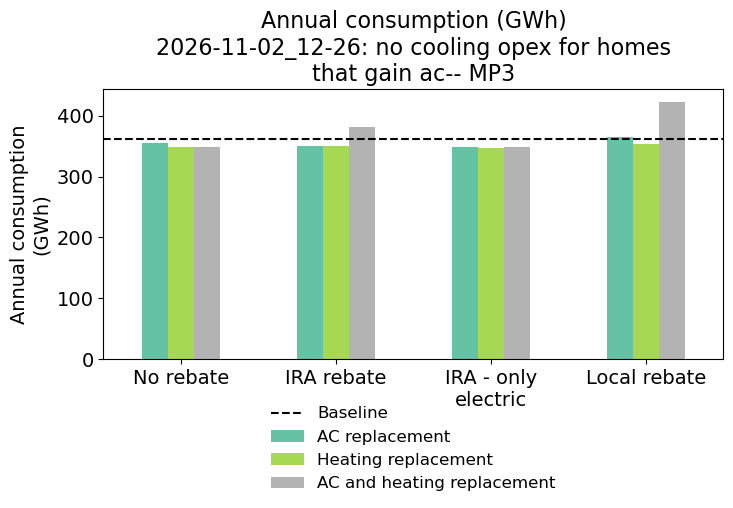

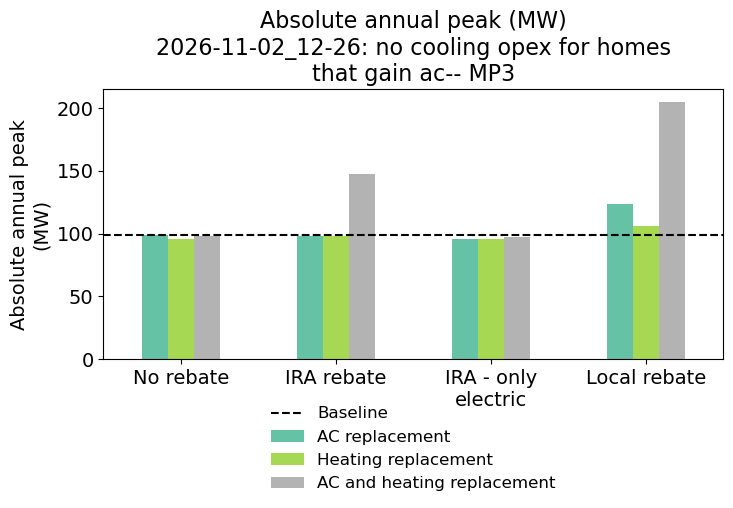

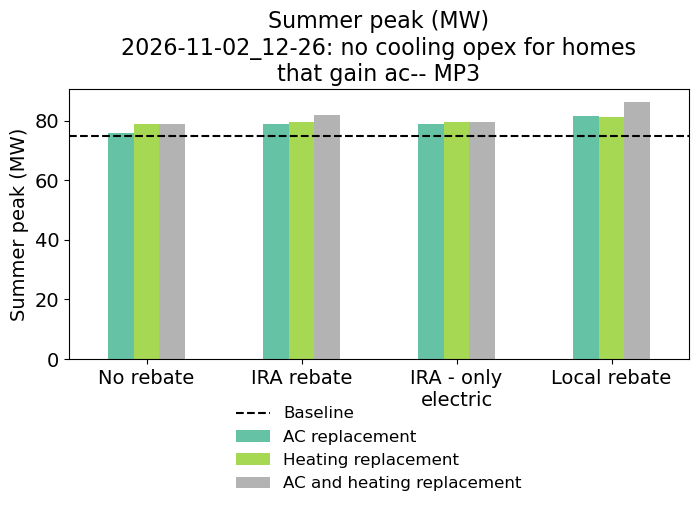

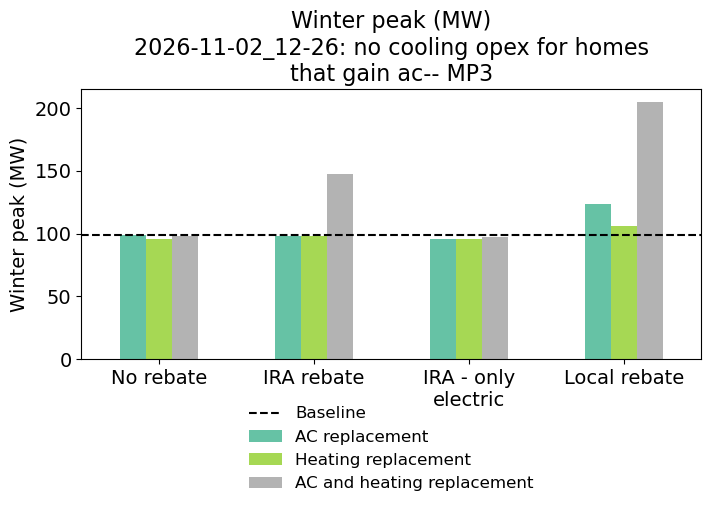

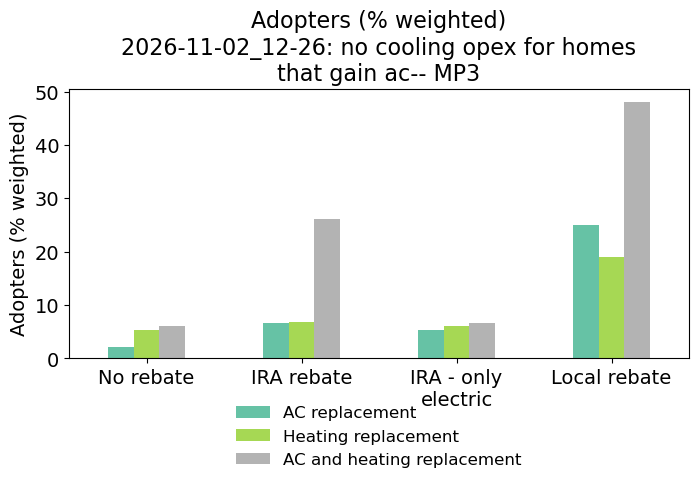

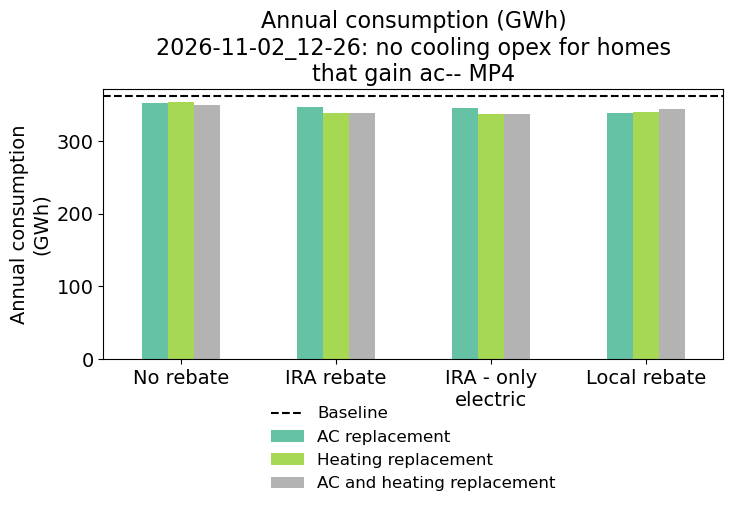

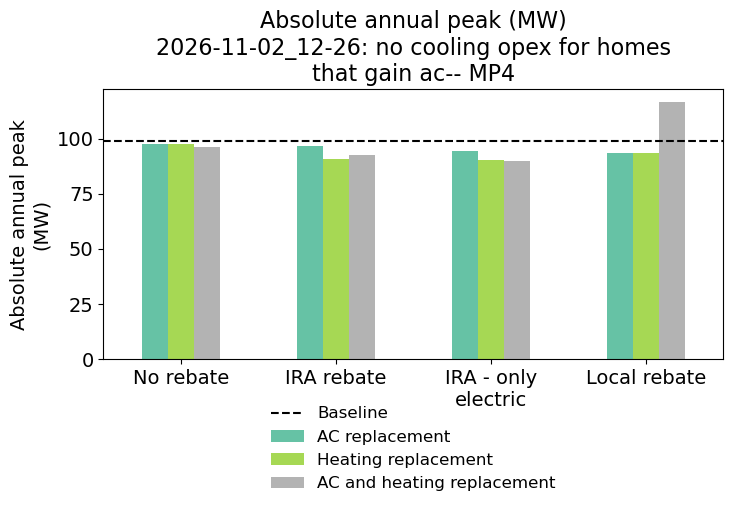

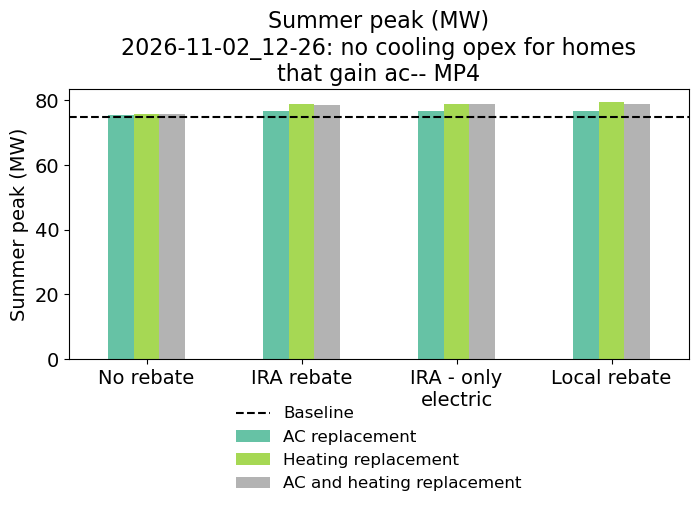

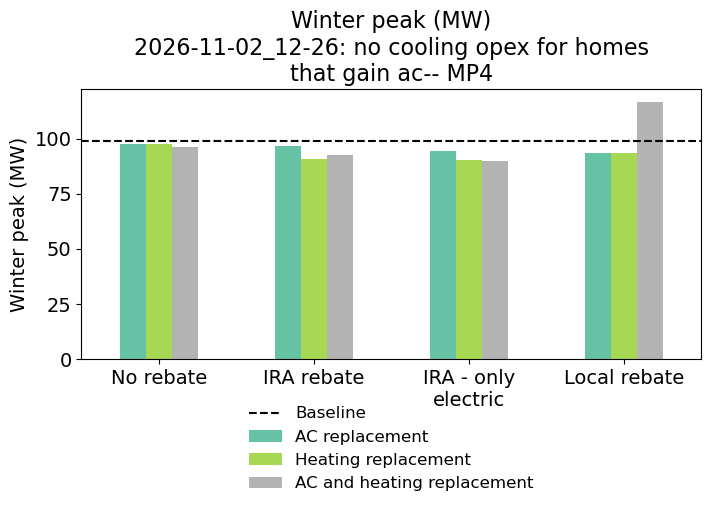

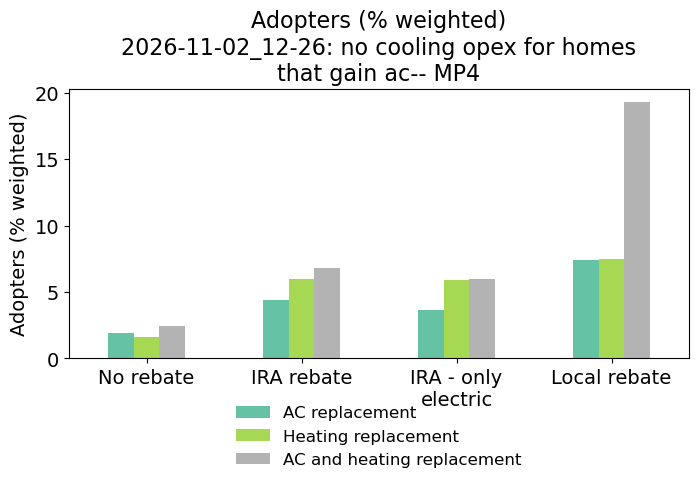

In [82]:
# Figure 2: replacement offset scopes within one run, for each MP
FIGURE2_RUN = RUN_DATETIMES[-1]
if FIGURE2_RUN not in RUN_DATETIMES:
    raise ValueError(
        f"FIGURE2_RUN must be one of {RUN_DATETIMES}, got {FIGURE2_RUN!r}"
    )
FIGURE2_METRICS = ENERGY_METRICS + ["Adopters (% weighted)"]

is_fig2_run = df_cmp["datetime"] == FIGURE2_RUN
df_fig2_base = df_cmp[is_fig2_run & (df_cmp["Scenario"] == "Baseline")]
# Time stamp and description, as in the run keys of the other figures
FIGURE2_LABEL = df_fig2_base["run"].item()

for mp in [3, 4]:
    df_fig2 = df_cmp[is_fig2_run & (df_cmp["MP"] == mp) & df_cmp["scope"].notna()]
    for metric in FIGURE2_METRICS:
        # Adopter shares have no Baseline value, so no dashed line is drawn
        run_baseline = df_fig2_base[metric].item()
        plot_clustered(
            df_fig2, metric, x="rebate", hue="scope",
            x_order=REBATE_ORDER, hue_order=SCOPE_ORDER,
            title=f"{metric} \n{FIGURE2_LABEL}-- MP{mp}",
            baseline=run_baseline,
            colormap="Set2"
        )


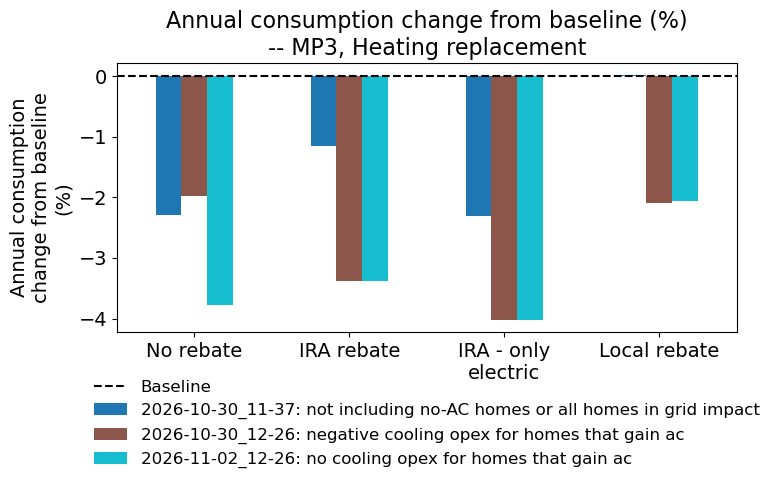

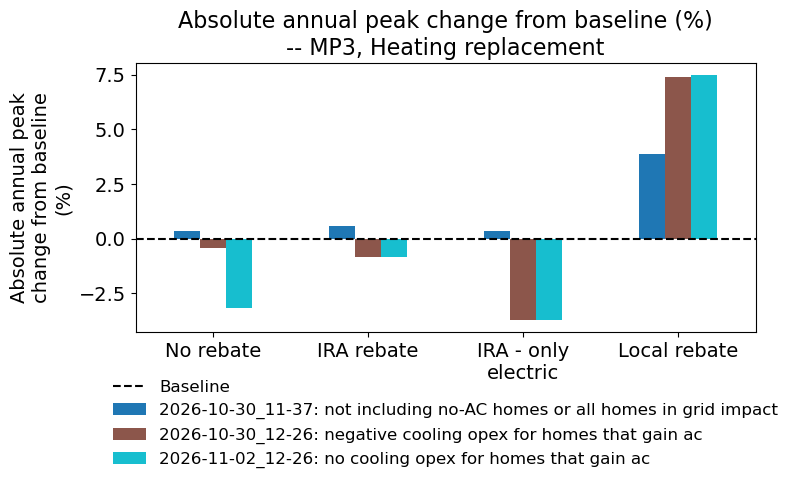

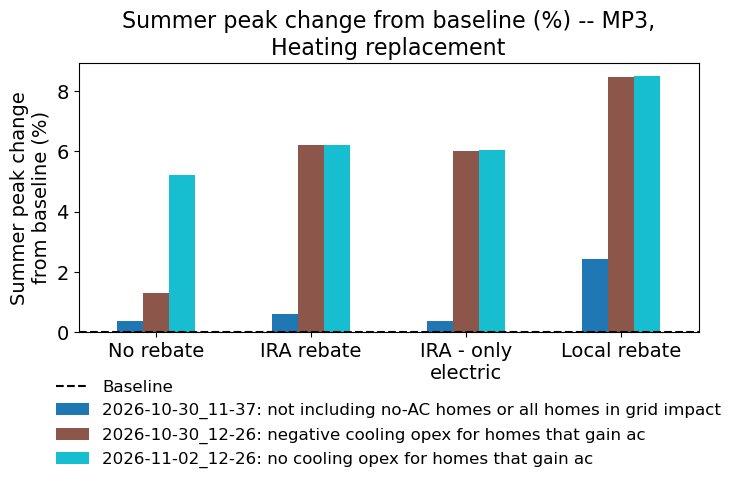

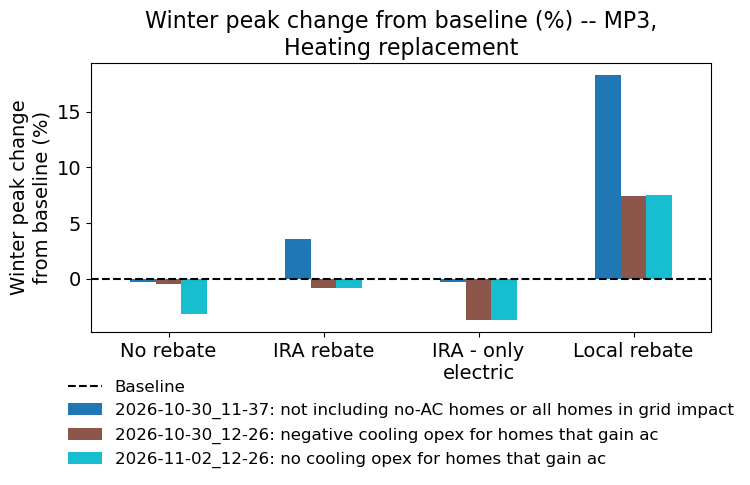

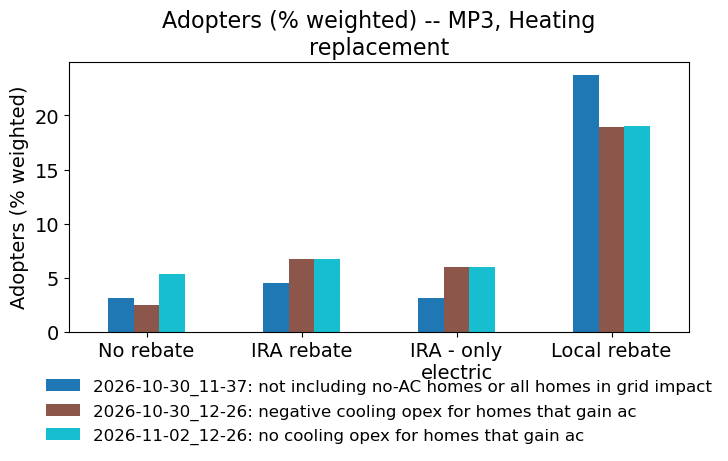

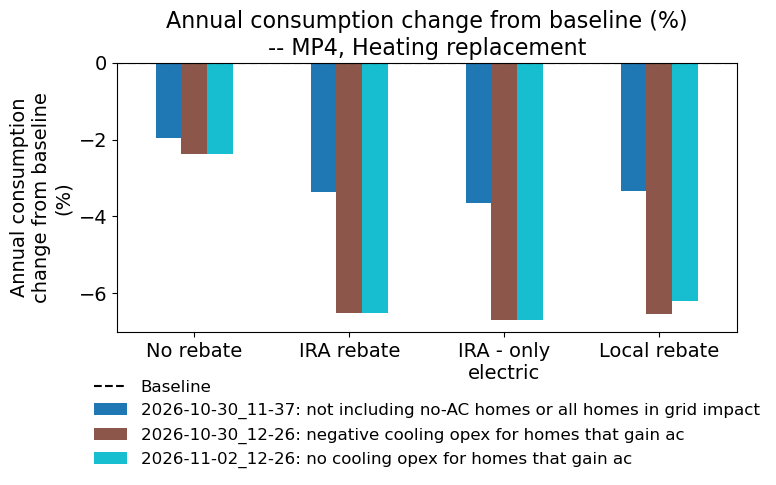

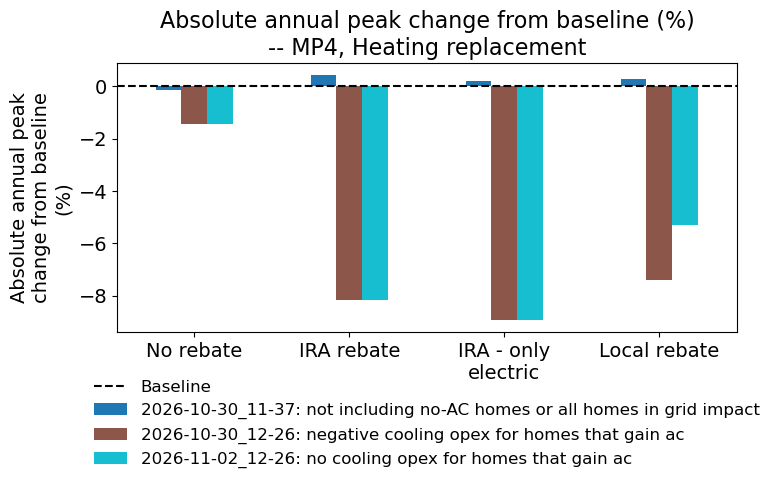

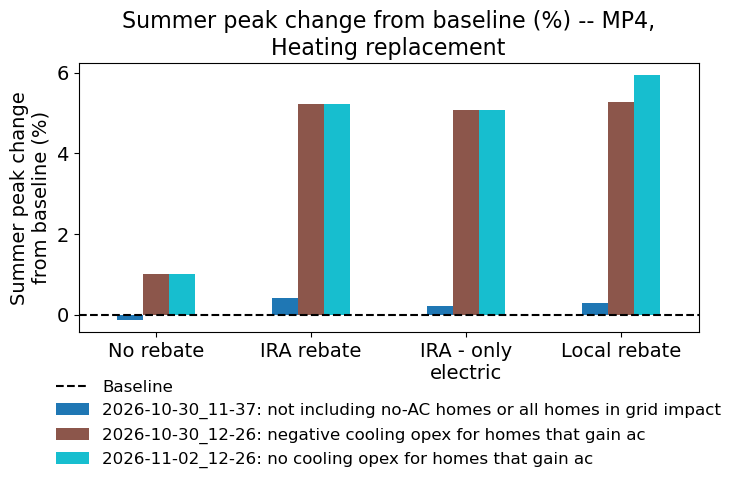

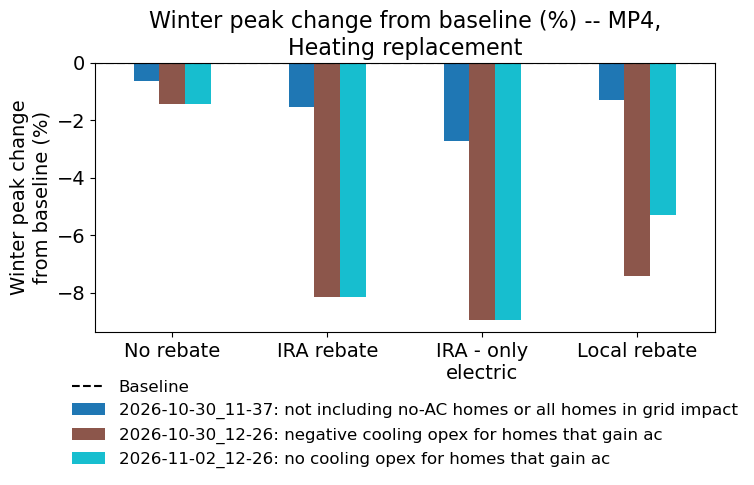

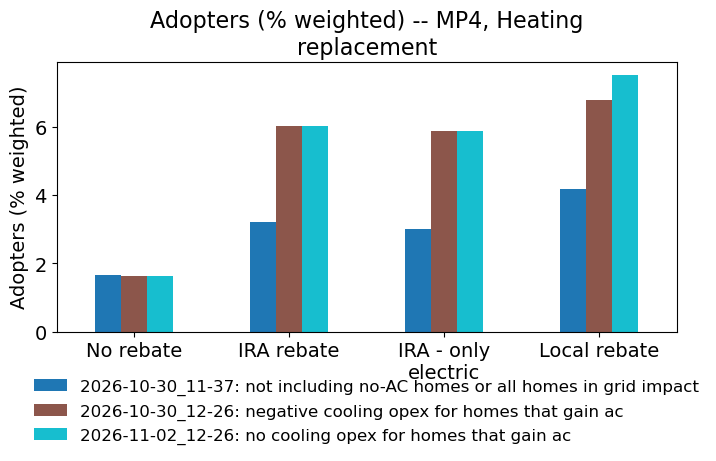

In [88]:
# Figure 3: rebate scenarios across runs, for one scope and each MP
FIGURE3_SCOPE = SCOPE_ORDER[0]
FIGURE3_SCOPE = 'heatingLCC_coolingSavings'

if FIGURE3_SCOPE not in SCOPE_ORDER:
    raise ValueError(
        f"FIGURE3_SCOPE must be one of {SCOPE_ORDER}, got {FIGURE3_SCOPE!r}"
    )
# Energy as % change, since runs can cover different homes
FIGURE3_METRICS = [
    metric.split(" (")[0] + " change from baseline (%)"
    for metric in ENERGY_METRICS
] + ["Adopters (% weighted)"]

for mp in [3, 4]:
    df_fig3 = df_cmp[(df_cmp["MP"] == mp) & (df_cmp["scope"] == FIGURE3_SCOPE)]
    for metric in FIGURE3_METRICS:
        # A dashed line at 0% marks each run's own baseline
        is_change = "change from baseline" in metric
        plot_clustered(
            df_fig3, metric, x="rebate", hue="run",
            x_order=REBATE_ORDER, colormap="tab10",
            title=f"{metric} -- MP{mp}, {PLAIN_LABELS[FIGURE3_SCOPE]}",
            baseline=0 if is_change else None,
        )


Base case scenario: heatingLCC_coolingSavings_sub_local


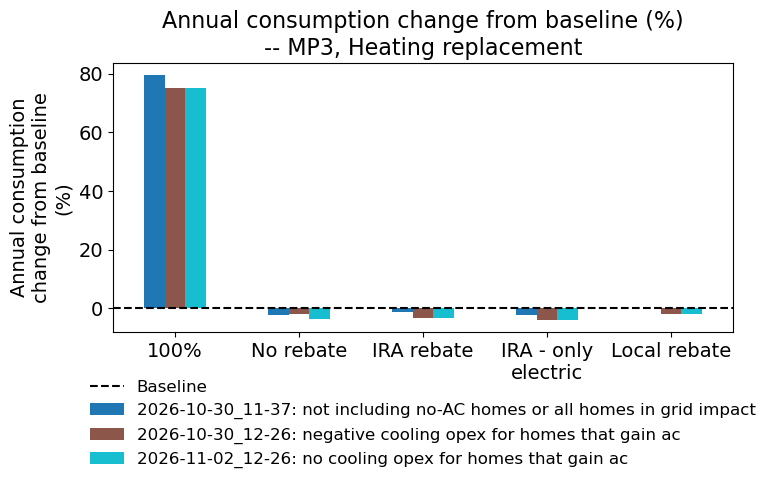

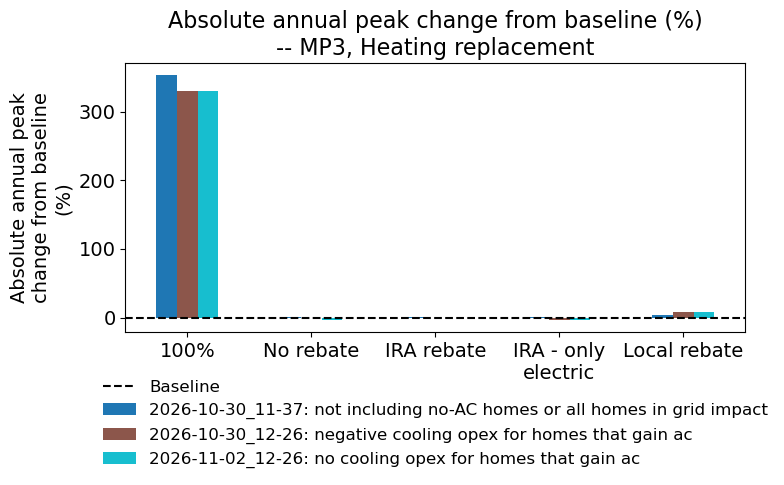

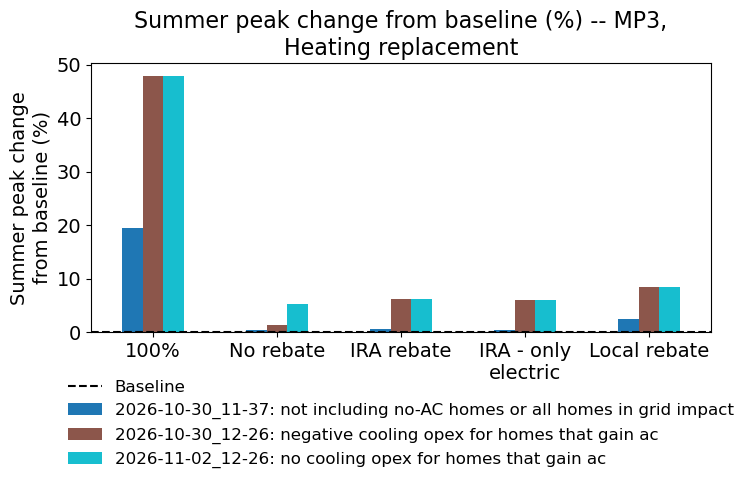

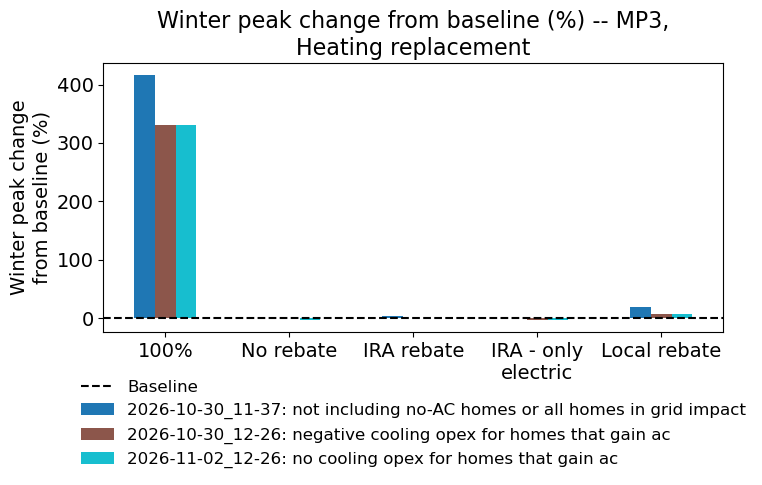

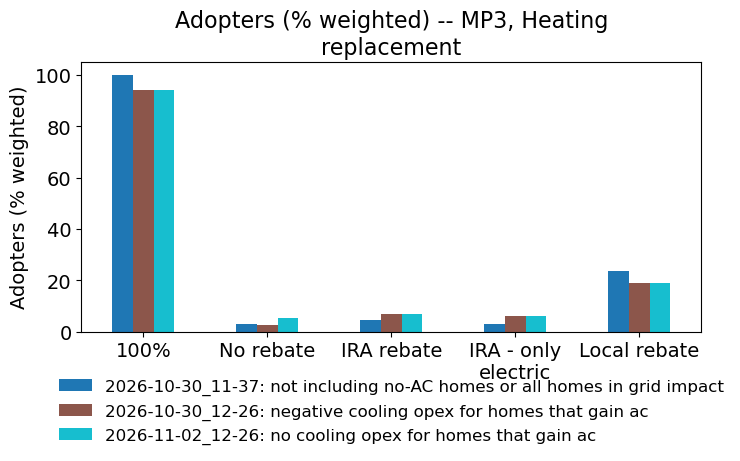

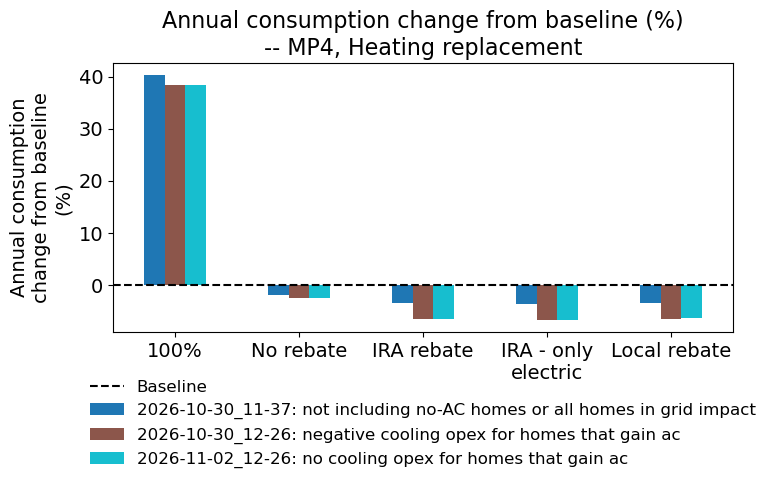

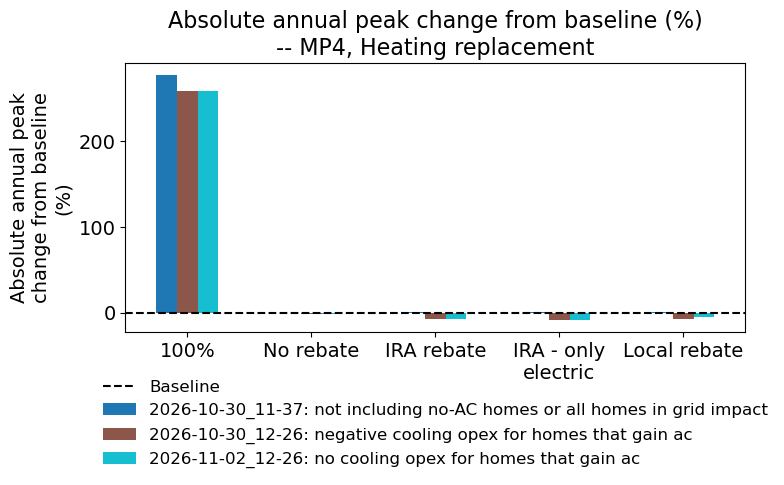

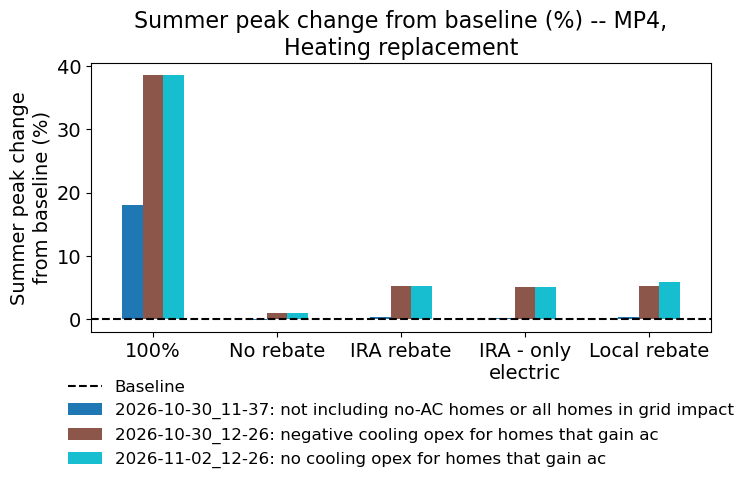

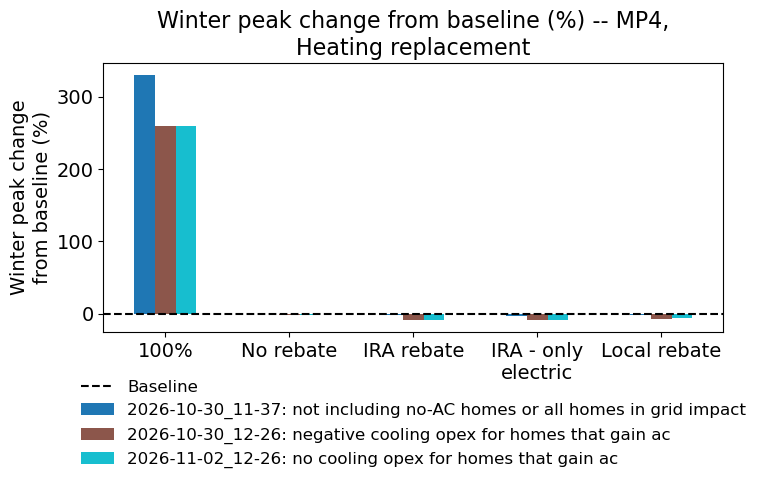

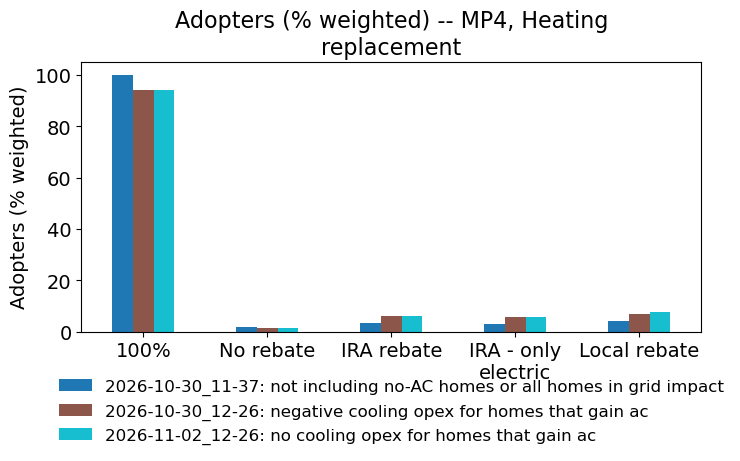

In [84]:
from constants import BASE_CASE_NPV_CASE
print(f"Base case scenario: {BASE_CASE_NPV_CASE}")


# Figure 4: the base case scope across runs, with each MP's 100% case
# Defaults to the scope of the project base case (constants.py)
BASE_SCOPE = "_".join(BASE_CASE_NPV_CASE.split("_")[:2])

# BASE_SCOPE =SCOPE_ORDER[2] #can update this to change rebate scenario 

if BASE_SCOPE not in SCOPE_ORDER:
    raise ValueError(
        f"BASE_SCOPE must be one of {SCOPE_ORDER}, got {BASE_SCOPE!r}"
    )
FIGURE4_ORDER = ["100%"] + REBATE_ORDER
FIGURE4_METRICS = [
    metric.split(" (")[0] + " change from baseline (%)"
    for metric in ENERGY_METRICS
] + ["Adopters (% weighted)"]

for mp in [3, 4]:
    is_mp = df_cmp["MP"] == mp
    is_100pct = df_cmp["Scenario"] == "100pct"
    df_fig4 = df_cmp[is_mp & (is_100pct | (df_cmp["scope"] == BASE_SCOPE))].copy()
    # The 100% rows have no rebate scenario, so they get their own cluster
    df_fig4["cluster"] = df_fig4["rebate"].fillna("100%")
    for metric in FIGURE4_METRICS:
        is_change = "change from baseline" in metric
        plot_clustered(
            df_fig4, metric, x="cluster", hue="run",
            x_order=FIGURE4_ORDER, colormap="tab10",
            title=f"{metric} -- MP{mp}, {PLAIN_LABELS[scope]}",
            baseline=0 if is_change else None,
        )


In [85]:
# Spot-check: the values behind the bars of Figures 3 and 4, MP3
check_metrics = [
    "Annual consumption change from baseline (%)",
    "Adopters (% weighted)",
]
df_check = df_cmp[df_cmp["MP"] == 3].copy()
df_check["cluster"] = df_check["rebate"].fillna("100%")

for scope in [FIGURE3_SCOPE, BASE_SCOPE]:
    is_shown = df_check["scope"].eq(scope) | df_check["Scenario"].eq("100pct")
    for metric in check_metrics:
        df_values = df_check[is_shown].pivot(
            index="cluster", columns="datetime", values=metric
        )
        print(f"\n{metric} -- MP3, {scope}")
        print(df_values.reindex(FIGURE4_ORDER).round(2).to_string())



Annual consumption change from baseline (%) -- MP3, heatingSavings_coolingLCC
datetime      2026-10-30_11-37  2026-10-30_12-26  2026-11-02_12-26
cluster                                                           
100%                     79.57             75.13             75.13
unsub                    -2.20             -1.24             -1.77
sub                      -1.49             -2.38             -3.32
sub_june2026             -2.22             -2.79             -3.73
sub_local                 5.41              1.52              0.95

Adopters (% weighted) -- MP3, heatingSavings_coolingLCC
datetime      2026-10-30_11-37  2026-10-30_12-26  2026-11-02_12-26
cluster                                                           
100%                    100.00             94.22             94.22
unsub                     2.98              1.76              2.21
sub                       5.23              4.95              6.62
sub_june2026              3.01              3.64            